# Praktikum 1

In [1]:
import torch
print("PyTorch Version:", torch.__version__)



cache_dir = "~/models"


PyTorch Version: 2.14.1+cu126


In [ ]:
import sys

print(sys.executable)
!df -h

/home/jovyan/conda/projekt/bin/python
Filesystem      Size  Used Avail Use% Mounted on
overlay         1.9T  179G  1.7T  10% /
tmpfs            64M     0   64M   0% /dev
tmpfs            30G  4.0K   30G   1% /dev/shm
/dev/rbd1        49G   30G   20G  60% /home/jovyan
/dev/nvme0n1p4  1.9T  179G  1.7T  10% /etc/hosts
none            378G  4.3M  378G   1% /run/nvidia-persistenced/socket
none            256K  256K     0 100% /usr/local/bin/nvidia-smi
rootfs          377G  587M  377G   1% /usr/lib/firmware/nvidia/580.178.04/gsp_ga10x.bin
tmpfs           4.0K  4.0K     0 100% /run/nvidia-ctk-hook04ef21ab-8303-4e48-b5a2-d37d069dff82
tmpfs           4.0K     0  4.0K   0% /proc/acpi


### Pipelines

In [8]:
from diffusers import StableDiffusionPipeline
from diffusers import DiffusionPipeline

# Stable Diffusion v1-5
def sd15_pipeline():
    return StableDiffusionPipeline.from_pretrained(
        "sd-legacy/stable-diffusion-v1-5",
        use_safetensors=True,
        trust_remote_code=True,
        cache_dir=cache_dir
    ).to("cuda")

def sdxl_pipeline():
    return DiffusionPipeline.from_pretrained(
        "stabilityai/stable-diffusion-xl-base-1.0", 
        torch_dtype=torch.float16, 
        use_safetensors=True, 
        variant="fp16"
    ).to("cuda")

pipeline = sdxl_pipeline()




/home/jovyan/conda/projekt/lib/python3.12/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 7/7 [00:01<00:00,  5.75it/s]


100%|██████████| 20/20 [00:05<00:00,  3.81it/s]
/home/jovyan/conda/projekt/lib/python3.12/site-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 20/20 [00:05<00:00,  3.80it/s]
There are modules in AutoencoderKL that should be kept in float32: [].

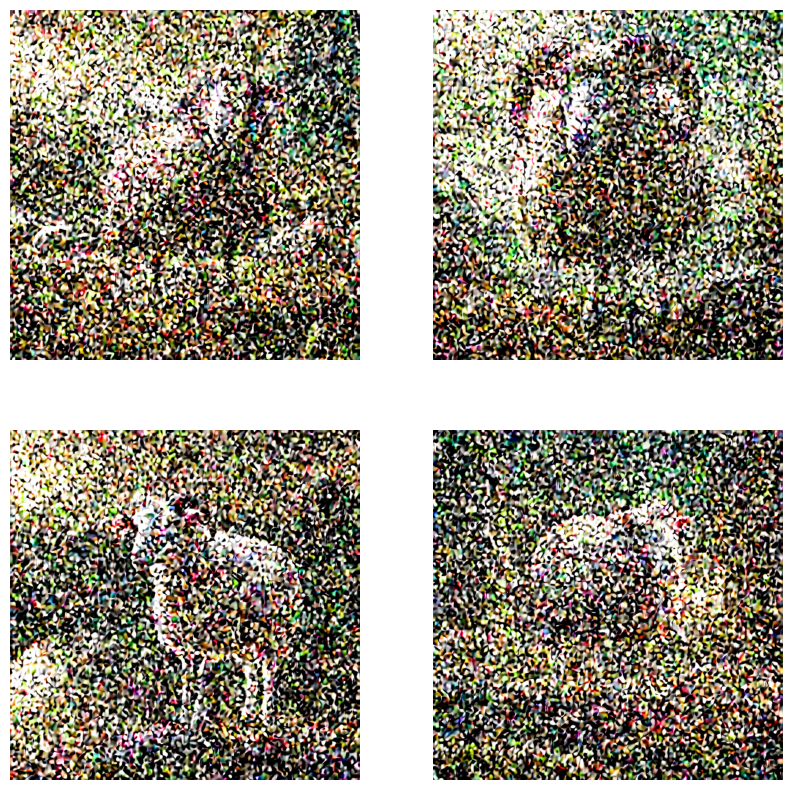

In [23]:
prompt = "a magical sheep in a fantasy landscape, highly detailed, cinematic lighting"
#image = pipeline(prompt=prompt, 
#                 num_inference_steps=40, 
#                 denoising_end=2.0
#).images[0]
#display(image)

images = []
for i in range(1, 5):
    image = pipeline(prompt=prompt, 
                     num_inference_steps=40,
                    denoising_end=0.5
    ).images[0]
    images.append(image)


# show images in a grid with matplotlib
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for i, ax in enumerate(axs.flatten()):
    ax.imshow(images[i])
    ax.axis('off')
